In [890]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings("ignore")

In [891]:
df = pd.read_csv('../data/marketing_data.csv')

In [892]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [893]:
df.tail()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
2235,10142,1976,PhD,Divorced,"$66,476.00",0,1,3/7/13,99,372,...,11,4,0,0,0,0,0,0,0,US
2236,5263,1977,2n Cycle,Married,"$31,056.00",1,0,1/22/13,99,5,...,3,8,0,0,0,0,0,0,0,SP
2237,22,1976,Graduation,Divorced,"$46,310.00",1,0,12/3/12,99,185,...,5,8,0,0,0,0,0,0,0,SP
2238,528,1978,Graduation,Married,"$65,819.00",0,0,11/29/12,99,267,...,10,3,0,0,0,0,0,0,0,IND
2239,4070,1969,PhD,Married,"$94,871.00",0,2,9/1/12,99,169,...,4,7,0,1,1,0,0,1,0,CA


In [894]:
df.sample(5)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
374,9289,1979,Graduation,Married,"$36,781.00",1,0,4/10/14,16,29,...,2,8,0,0,0,0,0,1,0,SP
2036,8867,1988,PhD,Married,"$67,546.00",0,0,8/31/12,90,864,...,5,3,0,0,0,0,0,0,0,SA
94,10582,1979,Graduation,Married,"$72,063.00",0,1,7/3/13,3,180,...,12,2,0,0,0,0,0,0,0,GER
1839,2002,1958,Graduation,Divorced,"$71,964.00",0,0,5/20/13,81,587,...,5,3,0,0,0,0,0,0,0,SP
1471,4887,1976,PhD,Divorced,"$55,412.00",1,1,11/22/13,65,10,...,3,5,0,0,0,0,0,0,0,CA


In [895]:
df.shape

(2240, 28)

In [896]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ',
       'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines',
       'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Response', 'Complain', 'Country'],
      dtype='str')

In [897]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   2240 non-null   int64
 1   Year_Birth           2240 non-null   int64
 2   Education            2240 non-null   str  
 3   Marital_Status       2240 non-null   str  
 4    Income              2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   Dt_Customer          2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProds         2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurchases      2240 non-null 

In [898]:
df.describe()

,ID,Year_Birth,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,...,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.149107,0.009375
std,3246.662198,11.984069,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,...,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.356274,0.096391
min,0.000000,1893.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,1970.000000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,1977.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [899]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
 Income                24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

In [900]:
missing = (df.isnull().sum()/len(df))*100

missing.sort_values(ascending=False)

 Income                1.071429
ID                     0.000000
Education              0.000000
Year_Birth             0.000000
Marital_Status         0.000000
Kidhome                0.000000
Teenhome               0.000000
Dt_Customer            0.000000
Recency                0.000000
MntWines               0.000000
MntFruits              0.000000
MntMeatProducts        0.000000
MntFishProducts        0.000000
MntSweetProducts       0.000000
MntGoldProds           0.000000
NumDealsPurchases      0.000000
NumWebPurchases        0.000000
NumCatalogPurchases    0.000000
NumStorePurchases      0.000000
NumWebVisitsMonth      0.000000
AcceptedCmp3           0.000000
AcceptedCmp4           0.000000
AcceptedCmp5           0.000000
AcceptedCmp1           0.000000
AcceptedCmp2           0.000000
Response               0.000000
Complain               0.000000
Country                0.000000
dtype: float64

In [901]:
df.dtypes

ID                     int64
Year_Birth             int64
Education                str
Marital_Status           str
 Income                  str
Kidhome                int64
Teenhome               int64
Dt_Customer              str
Recency                int64
MntWines               int64
MntFruits              int64
MntMeatProducts        int64
MntFishProducts        int64
MntSweetProducts       int64
MntGoldProds           int64
NumDealsPurchases      int64
NumWebPurchases        int64
NumCatalogPurchases    int64
NumStorePurchases      int64
NumWebVisitsMonth      int64
AcceptedCmp3           int64
AcceptedCmp4           int64
AcceptedCmp5           int64
AcceptedCmp1           int64
AcceptedCmp2           int64
Response               int64
Complain               int64
Country                  str
dtype: object

In [902]:
df[" Income "] = (
    df[" Income "]
      .str.replace(r"[$,]", "", regex=True)
)

df[" Income "] = pd.to_numeric(df[" Income "], errors="coerce")

In [903]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])

In [904]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   str           
 3   Marital_Status       2240 non-null   str           
 4    Income              2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[us]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-null   int64  

In [905]:
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [906]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64

In [907]:
df["Marital_Status"] = df["Marital_Status"].replace({
    "Together": "Married",
    "YOLO": "Single",
    "Absurd": "Single",
    "Alone": "Single"
})

In [908]:
df["Marital_Status"].value_counts()

Marital_Status
Married     1444
Single       487
Divorced     232
Widow         77
Name: count, dtype: int64

In [909]:
df[" Income "] = df.groupby(
    ["Education", "Marital_Status"]
)[" Income "].transform(
    lambda x: x.fillna(x.mean())
)

df[" Income "] = df.groupby("Education")[" Income "].transform(
    lambda x: x.fillna(x.mean())
)

df[" Income "] = df[" Income "].fillna(df[" Income "].median())

In [910]:
print(df[" Income "].dtype)

print(df[df[" Income "].isna()])

print(df[" Income "].head())

float64
Empty DataFrame
Columns: [ID, Year_Birth, Education, Marital_Status,  Income , Kidhome, Teenhome, Dt_Customer, Recency, MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds, NumDealsPurchases, NumWebPurchases, NumCatalogPurchases, NumStorePurchases, NumWebVisitsMonth, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, AcceptedCmp1, AcceptedCmp2, Response, Complain, Country]
Index: []

[0 rows x 28 columns]
0    84835.0
1    57091.0
2    67267.0
3    32474.0
4    21474.0
Name:  Income , dtype: float64


In [911]:
from datetime import datetime

current_year = datetime.now().year

df["Age"] = current_year - df["Year_Birth"]

In [912]:
df[["Year_Birth", "Age"]].head()

,Year_Birth,Age
0,1970,56
1,1961,65
2,1958,68
3,1967,59
4,1989,37


In [913]:
df["Children"] = df["Kidhome"] + df["Teenhome"]

In [914]:
df[["Kidhome", "Teenhome", "Children"]].head()

,Kidhome,Teenhome,Children
0,0,0,0
1,0,0,0
2,0,1,1
3,1,1,2
4,1,0,1


In [915]:
df["Total_Spending"] = (
    df["MntWines"]
    + df["MntFruits"]
    + df["MntMeatProducts"]
    + df["MntFishProducts"]
    + df["MntSweetProducts"]
    + df["MntGoldProds"]
)

df[[
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "Total_Spending"
]].head()

,MntWines,MntFruits,MntMeatProducts,Total_Spending
0,189,104,379,1190
1,464,5,64,577
2,134,11,59,251
3,10,0,1,11
4,6,16,24,91


In [916]:
df["Total_Purchases"] = (
    df["NumWebPurchases"]
    + df["NumCatalogPurchases"]
    + df["NumStorePurchases"]
)

df[[
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "Total_Purchases"
]].head()

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Total_Purchases
0,4,4,6,14
1,7,3,7,17
2,3,2,5,10
3,1,0,2,3
4,3,1,2,6


In [917]:
from datetime import datetime

today = pd.Timestamp(datetime.now())

df["Customer_Days"] = (today - df["Dt_Customer"]).dt.days

df[[
    "Age",
    "Children",
    "Total_Spending",
    "Total_Purchases"
]].head()

,Age,Children,Total_Spending,Total_Purchases
0,56,0,1190,14
1,65,0,577,17
2,68,1,251,10
3,59,2,11,3
4,37,1,91,6


In [918]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 33 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   str           
 3   Marital_Status       2240 non-null   str           
 4    Income              2240 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[us]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-null   int64  

In [919]:
numerical_features = [
    "Age",
    " Income ",
    "Children",
    "Total_Spending",
    "Total_Purchases",
    "Recency",
    "NumWebVisitsMonth"
]

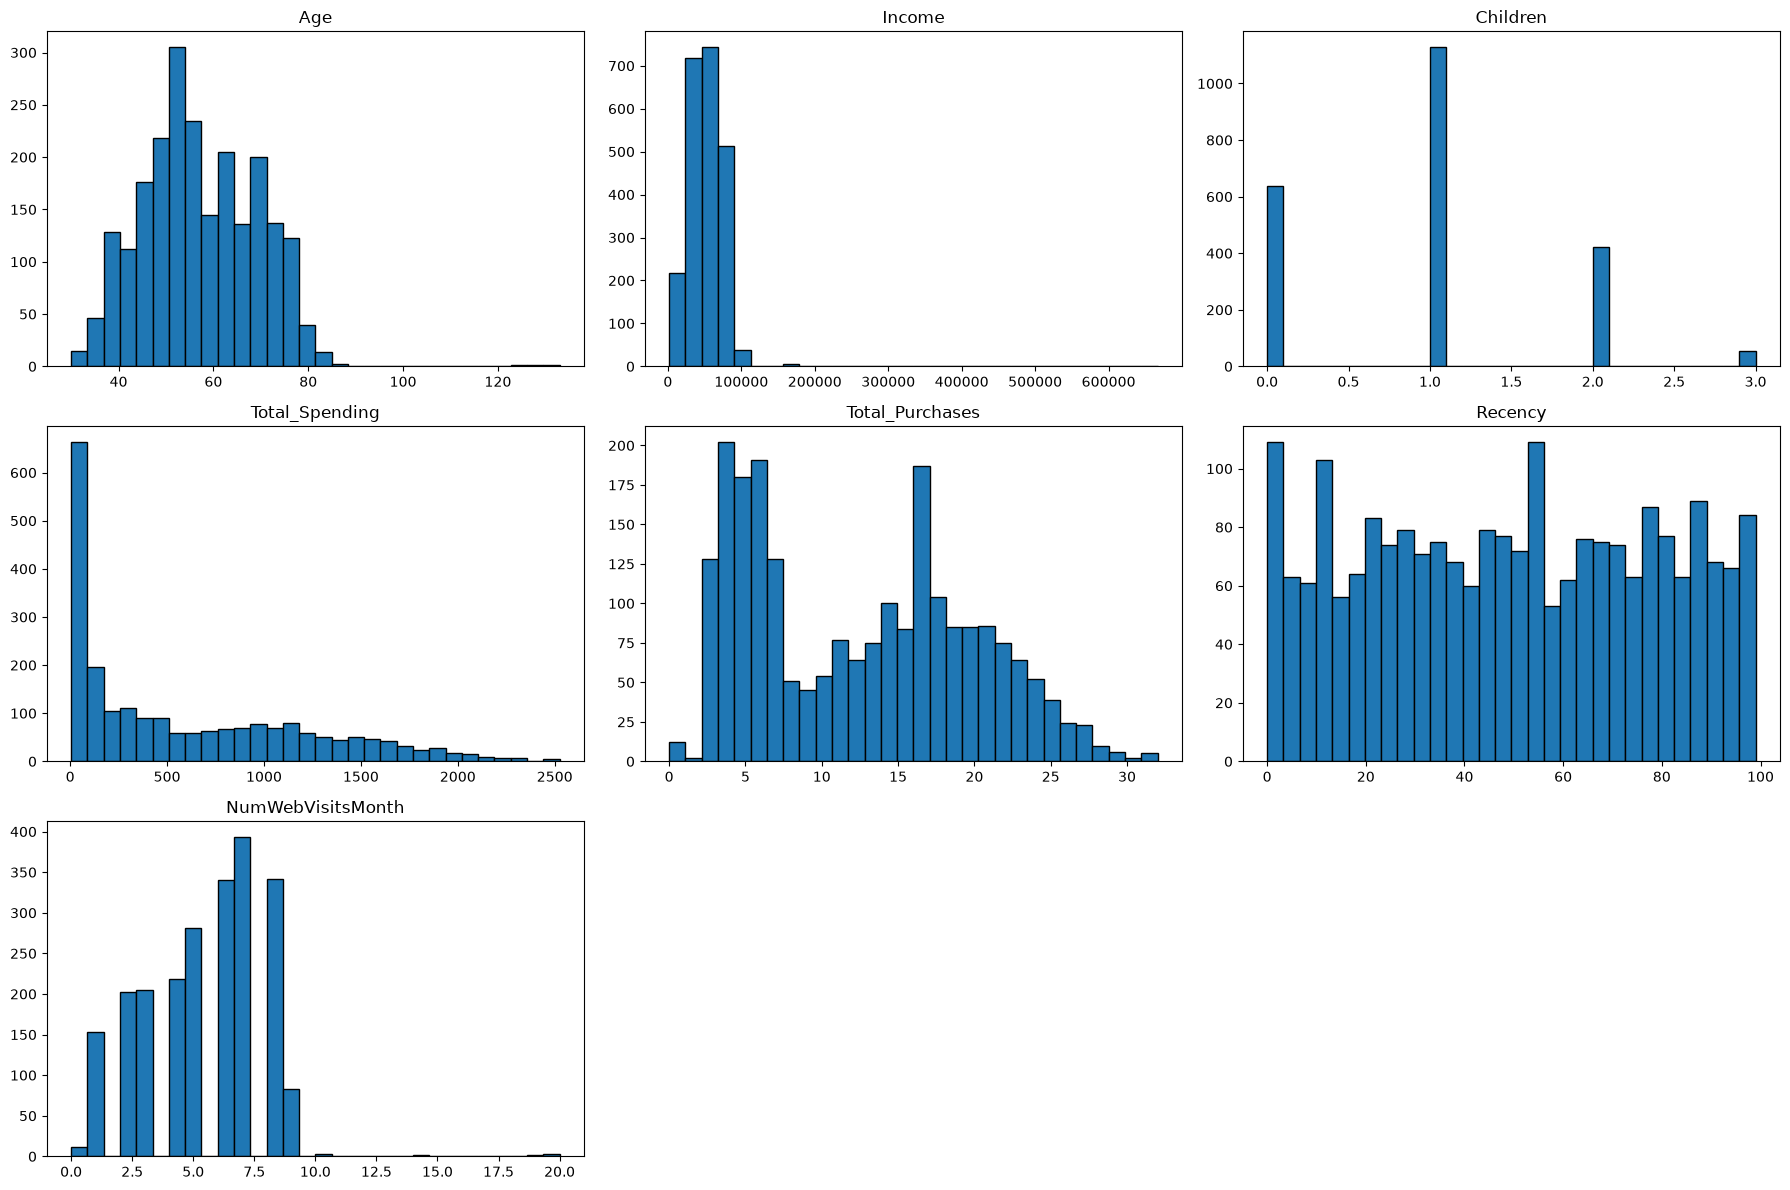

In [920]:
plt.figure(figsize=(18,12))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(3,3,i)
    plt.hist(df[column], bins=30, edgecolor="black")
    plt.title(column)

plt.tight_layout()
plt.show()

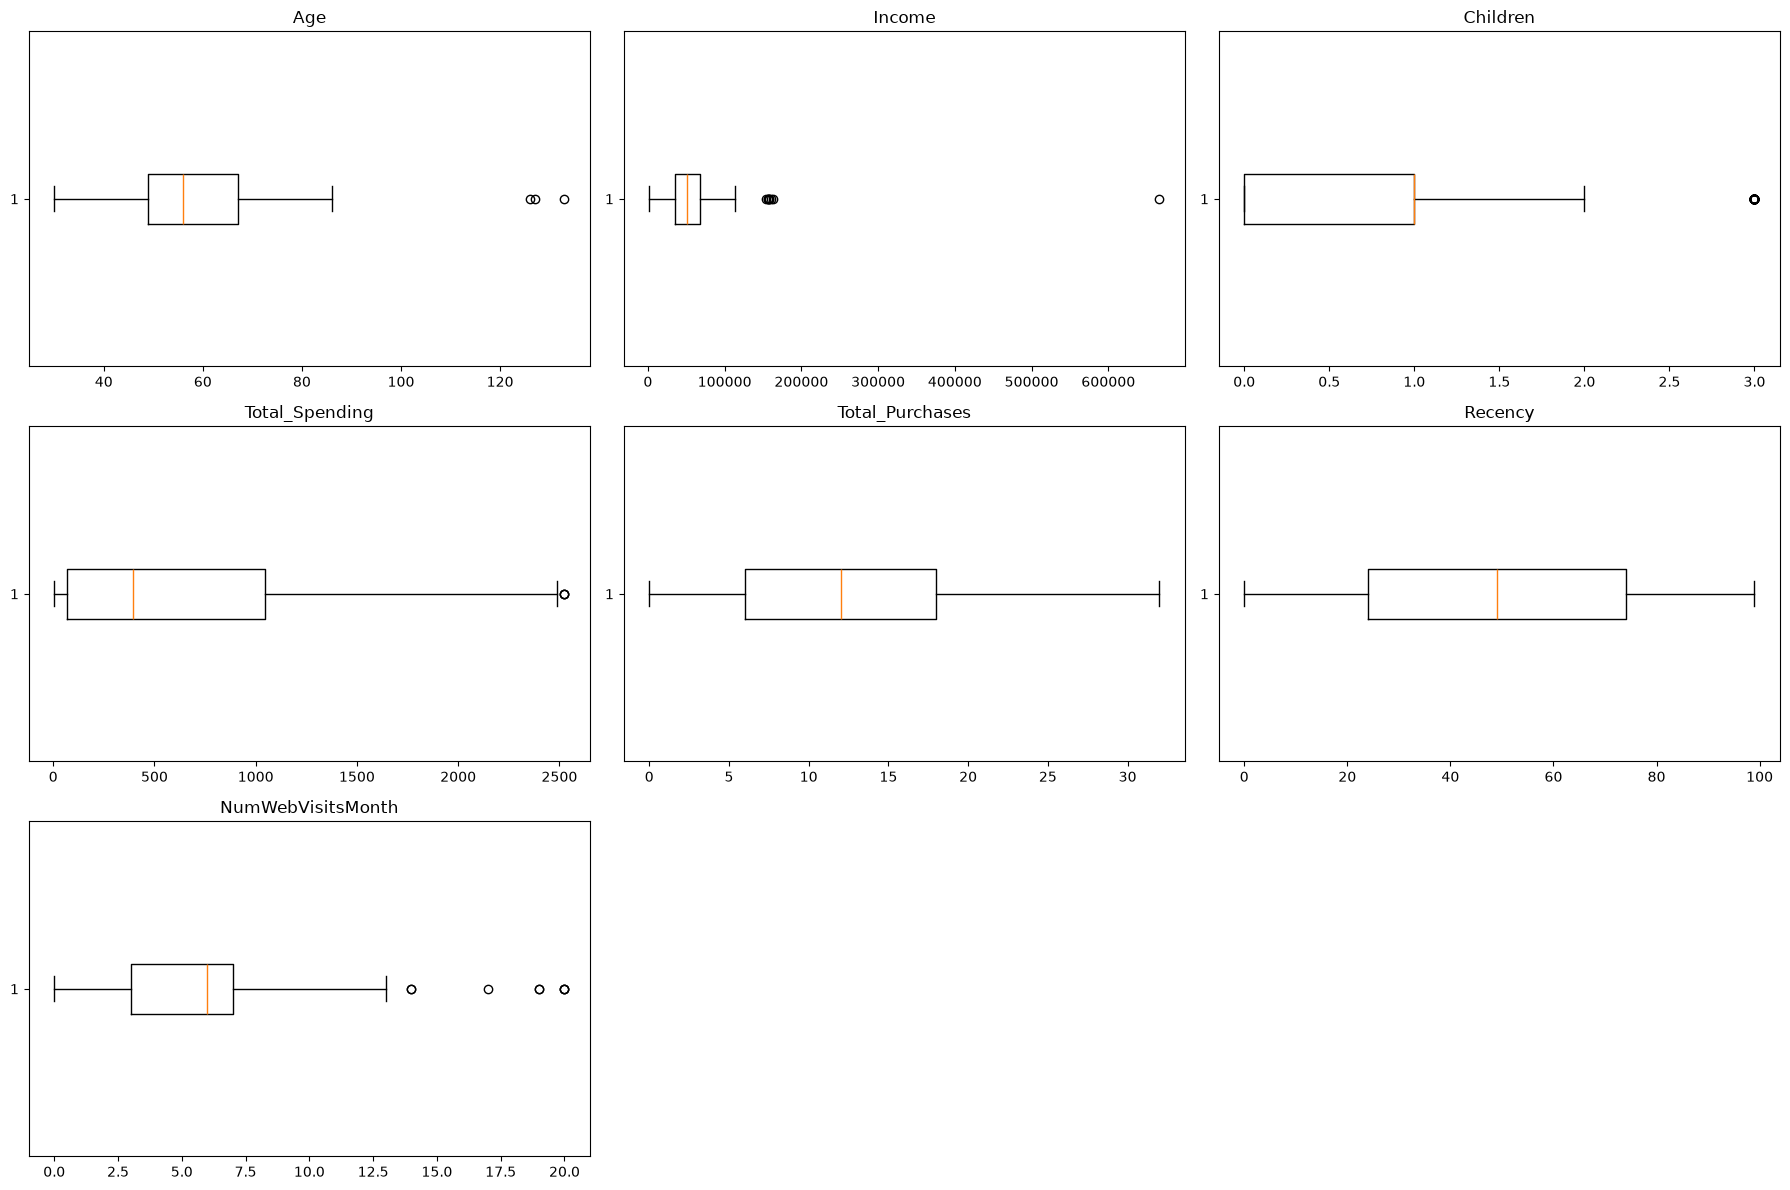

In [921]:
plt.figure(figsize=(18,12))

for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    plt.boxplot(df[column], vert=False)
    plt.title(column)

plt.tight_layout()
plt.show()

In [922]:
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower) | (data[column] > upper)]

    print(f"{column}")
    print(f"Lower Limit : {lower:.2f}")
    print(f"Upper Limit : {upper:.2f}")
    print(f"Outliers    : {len(outliers)}")
    print(" \n")

for column in numerical_features:
    detect_outliers(df, column)

Age
Lower Limit : 22.00
Upper Limit : 94.00
Outliers    : 3
 

 Income 
Lower Limit : -13587.75
Upper Limit : 117416.25
Outliers    : 8
 

Children
Lower Limit : -1.50
Upper Limit : 2.50
Outliers    : 53
 

Total_Spending
Lower Limit : -1396.38
Upper Limit : 2510.62
Outliers    : 3
 

Total_Purchases
Lower Limit : -12.00
Upper Limit : 36.00
Outliers    : 0
 

Recency
Lower Limit : -51.00
Upper Limit : 149.00
Outliers    : 0
 

NumWebVisitsMonth
Lower Limit : -3.00
Upper Limit : 13.00
Outliers    : 8
 



In [923]:
df[df["Age"] > 100]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Age,Children,Total_Spending,Total_Purchases,Customer_Days
513,11004,1893,2n Cycle,Single,60182.0,0,1,2014-05-17,23,8,...,0,0,0,0,SA,133,1,22,3,4457
827,1150,1899,PhD,Married,83532.0,0,0,2013-09-26,36,755,...,0,0,0,0,SP,127,0,1853,14,4690
2233,7829,1900,2n Cycle,Divorced,36640.0,1,0,2013-09-26,99,15,...,0,0,0,1,IND,126,1,65,5,4690


In [924]:
df = df[df["Age"] <= 100]

In [925]:
df.shape

(2237, 33)

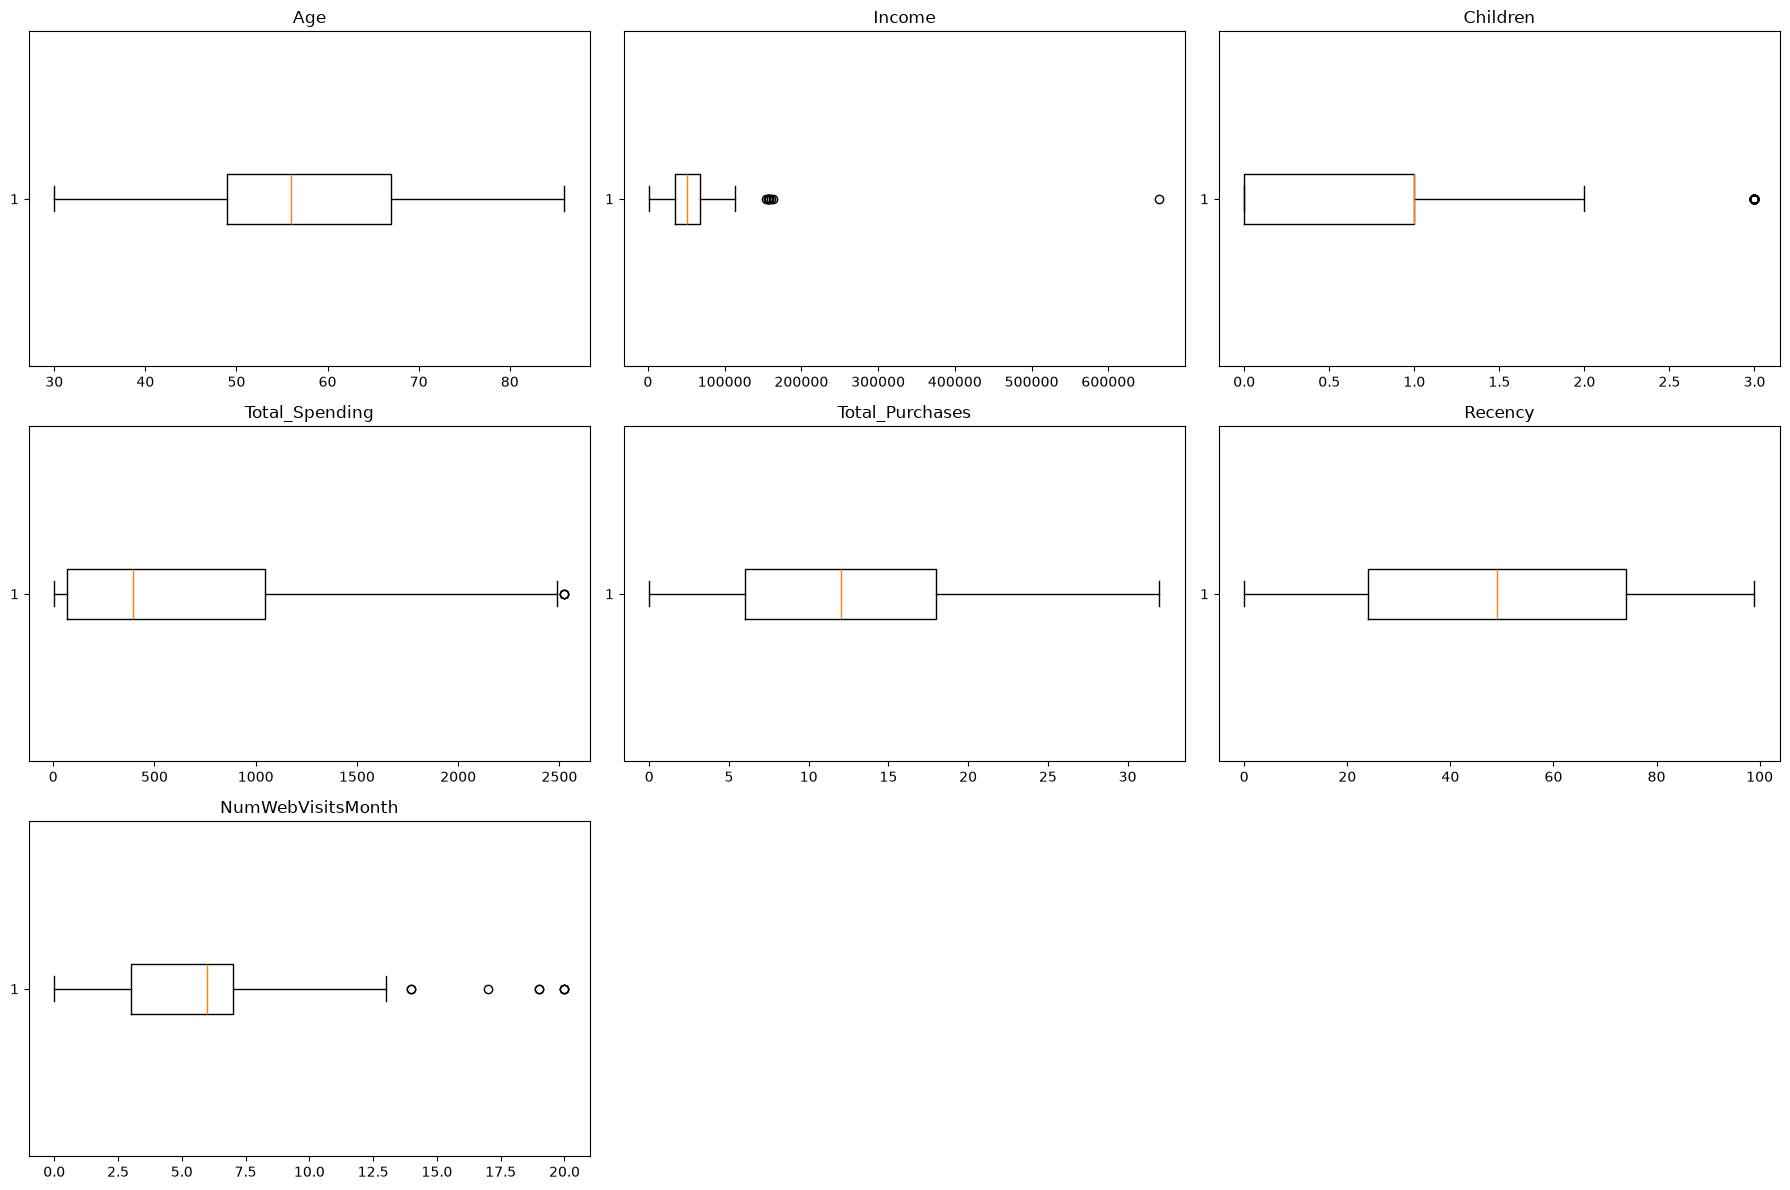

In [926]:
plt.figure(figsize=(18,12))

for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    plt.boxplot(df[column], vert=False)
    plt.title(column)

plt.tight_layout()
plt.show()

In [927]:
df_encoded = df.copy()

In [928]:
education_mapping = {
    "Basic": 0,
    "2n Cycle": 1,
    "Graduation": 2,
    "Master": 3,
    "PhD": 4
}

df_encoded["Education"] = df_encoded["Education"].map(education_mapping)

df_encoded[["Education"]].head()

,Education
0,2
1,2
2,2
3,2
4,2


In [929]:
df_encoded = pd.get_dummies(
    df_encoded,
    columns=["Marital_Status", "Country"],
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.DataFrame'>
Index: 2237 entries, 0 to 2239
Data columns (total 41 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   ID                      2237 non-null   int64         
 1   Year_Birth              2237 non-null   int64         
 2   Education               2237 non-null   int64         
 3    Income                 2237 non-null   float64       
 4   Kidhome                 2237 non-null   int64         
 5   Teenhome                2237 non-null   int64         
 6   Dt_Customer             2237 non-null   datetime64[us]
 7   Recency                 2237 non-null   int64         
 8   MntWines                2237 non-null   int64         
 9   MntFruits               2237 non-null   int64         
 10  MntMeatProducts         2237 non-null   int64         
 11  MntFishProducts         2237 non-null   int64         
 12  MntSweetProducts        2237 non-null   int64         
 13  MntG

In [930]:
df_encoded.to_csv("marketing_campaign_cleaned_encoded.csv", index=False)

In [931]:
correlation_matrix = df_encoded.corr(numeric_only=True)

correlation_matrix.head()

,ID,Year_Birth,Education,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,Marital_Status_Married,Marital_Status_Single,Marital_Status_Widow,Country_CA,Country_GER,Country_IND,Country_ME,Country_SA,Country_SP,Country_US
ID,1.000000,0.003024,-0.000496,0.013545,0.002202,-0.003543,-0.046755,-0.021181,0.007080,-0.002622,...,0.020844,-0.020498,0.022046,0.018099,-0.038526,-0.001685,0.002074,0.012139,-0.008526,0.009003
Year_Birth,0.003024,1.000000,-0.193869,-0.162871,0.234133,-0.363350,-0.019670,-0.163035,-0.013751,-0.030927,...,-0.001125,0.125161,-0.166922,-0.025844,-0.003595,0.057744,0.010749,0.018186,-0.002707,-0.010343
Education,-0.000496,-0.193869,1.000000,0.148699,-0.053068,0.135692,-0.013926,0.212500,-0.077928,0.041904,...,-0.010296,-0.018357,0.042798,-0.003454,-0.042133,-0.040909,0.019691,0.048815,0.012293,-0.019115
Income,0.013545,-0.162871,0.148699,1.000000,-0.424605,0.019333,-0.003195,0.576739,0.428485,0.576836,...,0.004040,-0.025535,0.032160,0.012143,0.006374,-0.033513,0.007960,0.043208,-0.027553,0.008758
Kidhome,0.002202,0.234133,-0.053068,-0.424605,1.000000,-0.035753,0.007544,-0.496367,-0.372488,-0.437059,...,0.023966,0.020233,-0.073854,-0.018116,-0.019612,0.035796,-0.030247,0.034166,-0.031750,-0.017100


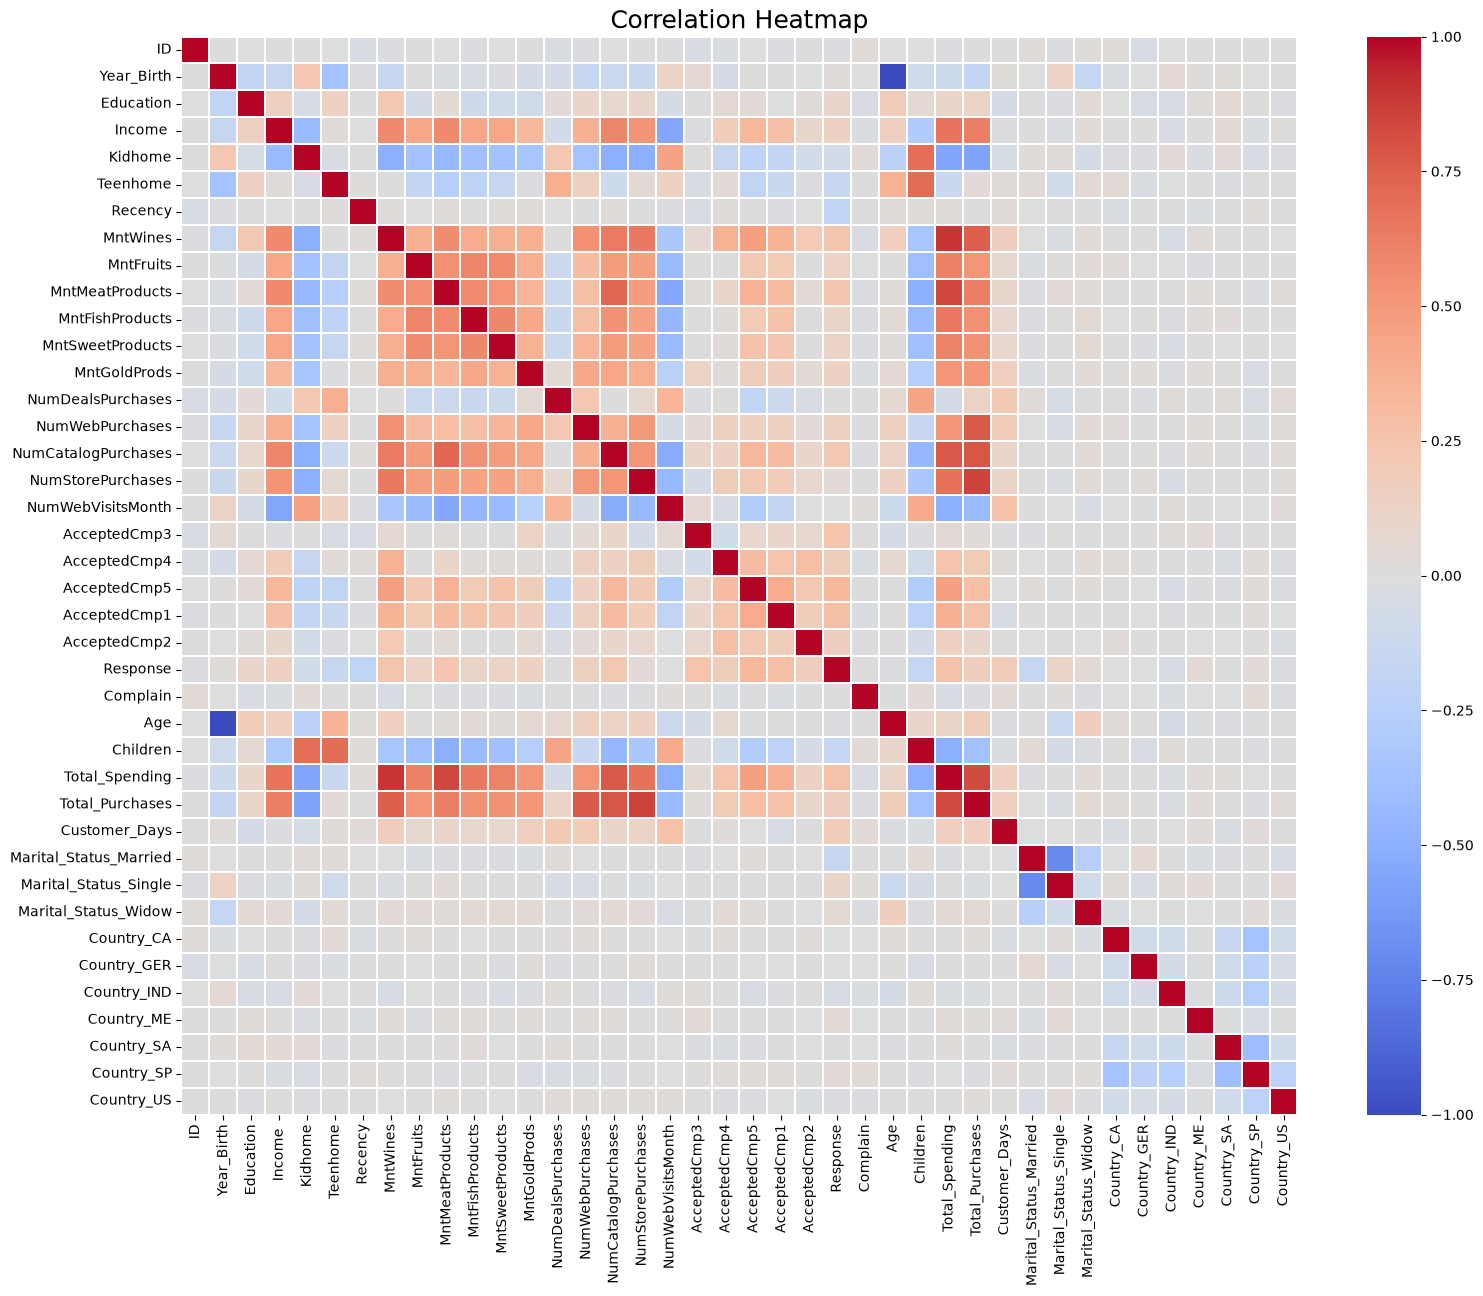

In [932]:
plt.figure(figsize=(18,14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap", fontsize=18)

plt.show()

In [933]:
corr_pairs = (
    correlation_matrix
    .unstack()
    .sort_values(ascending=False)
) # type: ignore

corr_pairs = corr_pairs[corr_pairs != 1]

corr_pairs.head(20)

Total_Spending       MntWines               0.891734
MntWines             Total_Spending         0.891734
NumStorePurchases    Total_Purchases        0.855399
Total_Purchases      NumStorePurchases      0.855399
Total_Spending       MntMeatProducts        0.842655
MntMeatProducts      Total_Spending         0.842655
Total_Purchases      Total_Spending         0.821143
Total_Spending       Total_Purchases        0.821143
NumCatalogPurchases  Total_Purchases        0.785639
Total_Purchases      NumCatalogPurchases    0.785639
Total_Spending       NumCatalogPurchases    0.778375
NumCatalogPurchases  Total_Spending         0.778375
Total_Purchases      NumWebPurchases        0.765720
NumWebPurchases      Total_Purchases        0.765720
Total_Purchases      MntWines               0.756494
MntWines             Total_Purchases        0.756494
NumCatalogPurchases  MntMeatProducts        0.723519
MntMeatProducts      NumCatalogPurchases    0.723519
Children             Teenhome               0.

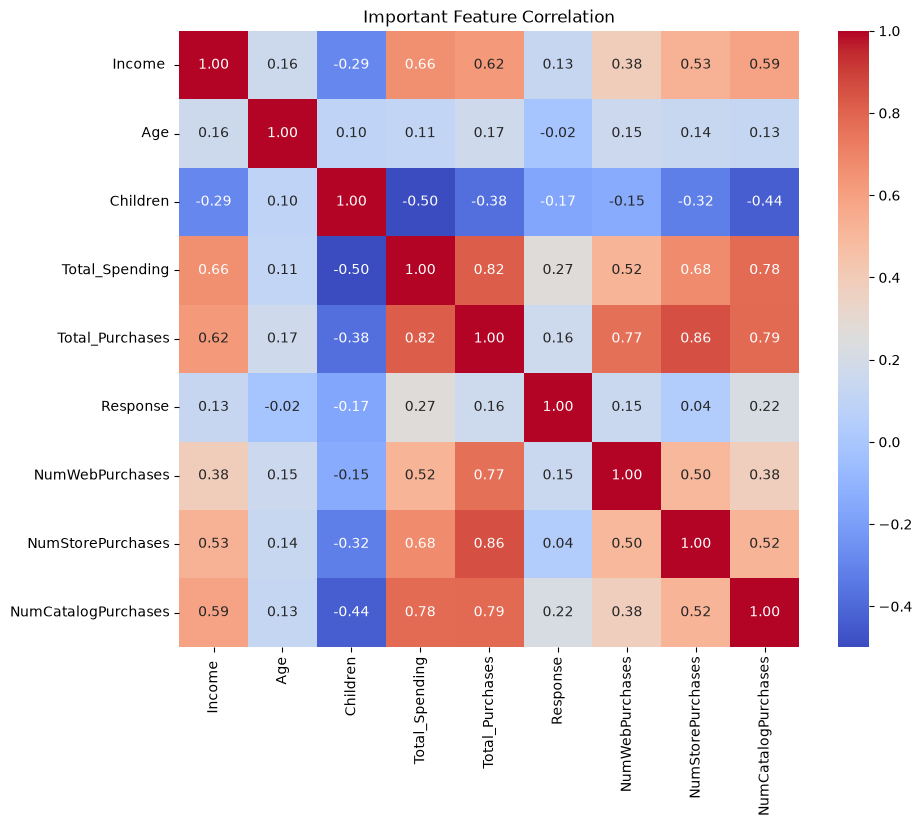

In [934]:
important_columns = [
    " Income ",
    "Age",
    "Children",
    "Total_Spending",
    "Total_Purchases",
    "Response",
    "NumWebPurchases",
    "NumStorePurchases",
    "NumCatalogPurchases"
]

plt.figure(figsize=(10,8))

sns.heatmap(
    df_encoded[important_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Important Feature Correlation")

plt.show()

In [935]:
from scipy.stats import pearsonr

def correlation_test(data, col1, col2):
    from scipy.stats import pearsonr

    corr, p = pearsonr(data[col1], data[col2])

    print(" ")
    print(f"{col1} vs {col2}")
    print(" ")
    print(f"Correlation : {corr:.3f}")
    print(f"P-value     : {p:.5f}")

    if p < 0.05: # type: ignore
        print("Statistical Decision : Reject H₀")
    else:
        print("Statistical Decision : Fail to Reject H₀")

    if corr > 0: # type: ignore
        print("Relationship         : Positive")
    elif corr < 0: # type: ignore
        print("Relationship         : Negative")
    else:
        print("Relationship         : No Linear Relationship")

In [936]:
correlation_test(df, "Age", "NumStorePurchases")

 
Age vs NumStorePurchases
 
Correlation : 0.139
P-value     : 0.00000
Statistical Decision : Reject H₀
Relationship         : Positive


In [937]:
correlation_test(df, "Children", "NumWebPurchases")

 
Children vs NumWebPurchases
 
Correlation : -0.146
P-value     : 0.00000
Statistical Decision : Reject H₀
Relationship         : Negative


In [938]:
correlation_test(df, "NumStorePurchases", "NumWebPurchases")

 
NumStorePurchases vs NumWebPurchases
 
Correlation : 0.502
P-value     : 0.00000
Statistical Decision : Reject H₀
Relationship         : Positive


In [939]:
usa = df[df["Country"] == "US"]["Total_Purchases"]

rest = df[df["Country"] != "US"]["Total_Purchases"]

In [940]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    usa,
    rest,
    equal_var=False
)

print("T Statistic :", round(t_stat,3)) # type: ignore
print("P-value :", p_value)

alpha = 0.05

if p_value < alpha: # type: ignore
    print("Reject H0")
else:
    print("Fail to Reject H0")

T Statistic : 1.458
P-value : 0.1475291718629341
Fail to Reject H0


In [941]:
product_sales = {
    "Wines": df["MntWines"].sum(),
    "Fruits": df["MntFruits"].sum(),
    "Meat": df["MntMeatProducts"].sum(),
    "Fish": df["MntFishProducts"].sum(),
    "Sweets": df["MntSweetProducts"].sum(),
    "Gold": df["MntGoldProds"].sum()
}

product_sales = pd.Series(product_sales).sort_values(ascending=False)

print(product_sales)

Wines     680038
Meat      373393
Gold       98358
Fish       83939
Sweets     60553
Fruits     58767
dtype: int64


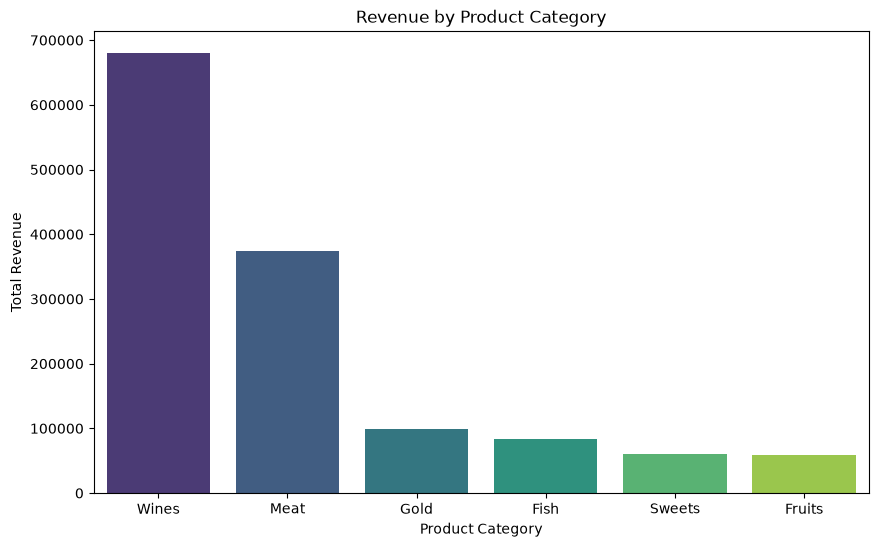

In [942]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=product_sales.index, # type: ignore
    y=product_sales.values, # type: ignore
    palette="viridis"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.show()

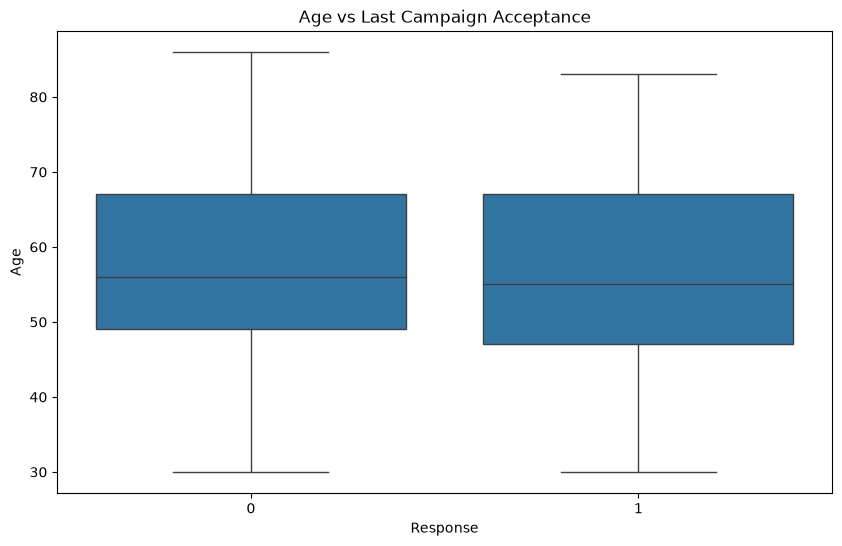

In [943]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x="Response",
    y="Age",
    data=df
)

plt.title("Age vs Last Campaign Acceptance")

plt.show()

In [944]:
country_response = (
    df[df["Response"] == 1]
    .groupby("Country")
    .size()
    .sort_values(ascending=False)
)

print(country_response)

Country
SP     176
SA      52
CA      38
AUS     23
GER     17
IND     13
US      13
ME       2
dtype: int64


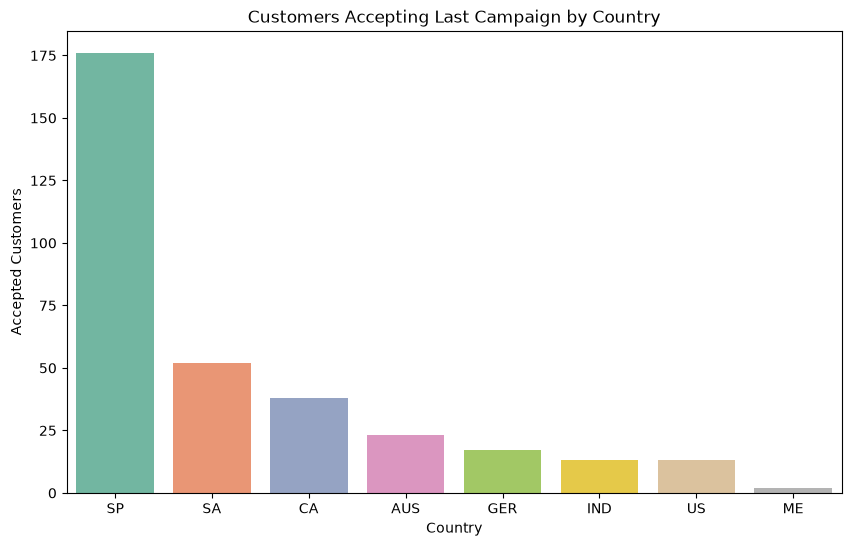

In [945]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=country_response.index,
    y=country_response.values,
    palette="Set2"
)

plt.title("Customers Accepting Last Campaign by Country")

plt.xlabel("Country")

plt.ylabel("Accepted Customers")

plt.show()

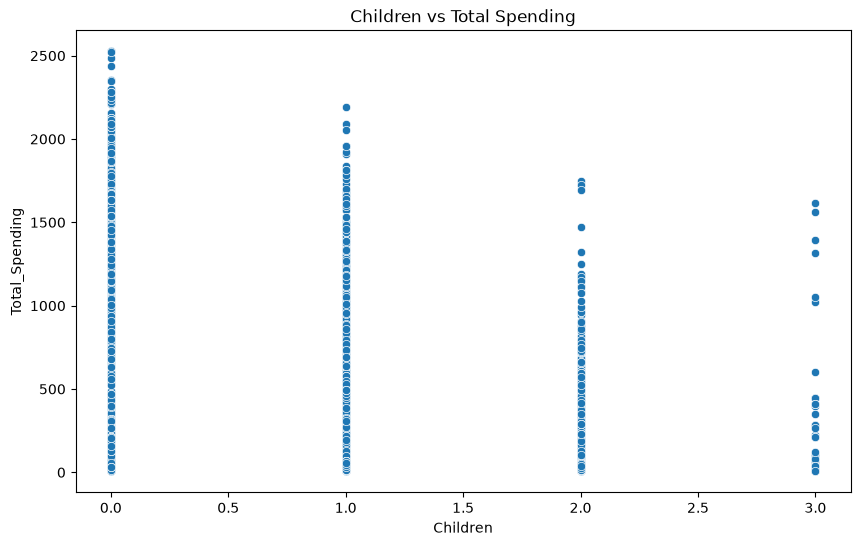

In [946]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Children",
    y="Total_Spending",
    data=df
)

plt.title("Children vs Total Spending")

plt.show()

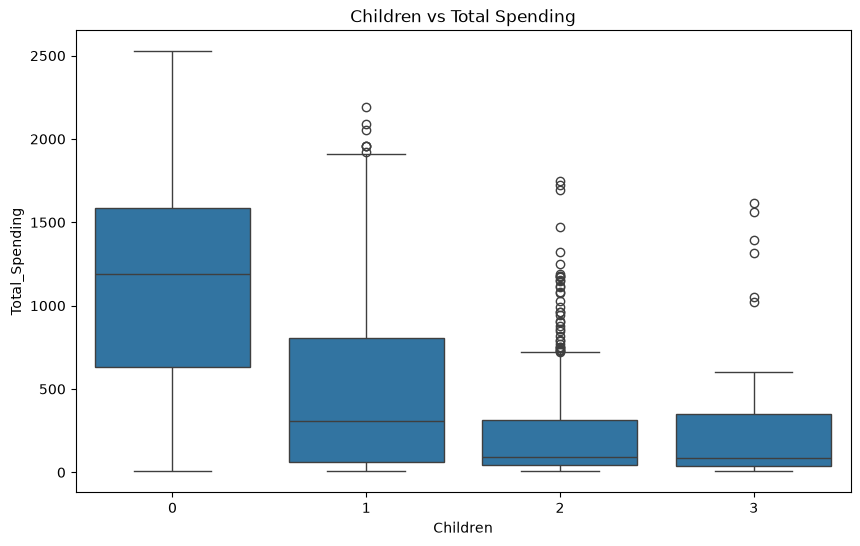

In [947]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x="Children",
    y="Total_Spending",
    data=df
)

plt.title("Children vs Total Spending")

plt.show()

In [948]:
complaints = df[df["Complain"] == 1]

education_counts = complaints["Education"].value_counts()

print(education_counts)

Education
Graduation    14
2n Cycle       3
Master         2
PhD            1
Name: count, dtype: int64


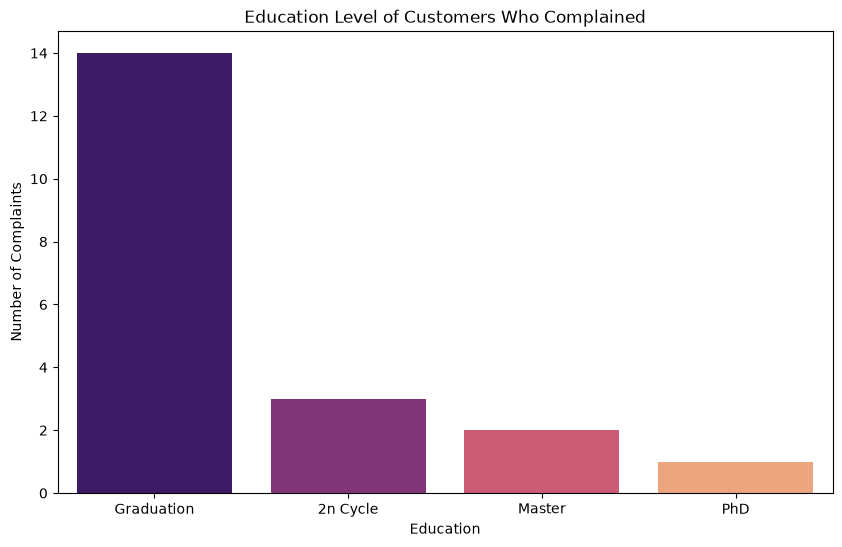

In [949]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=education_counts.index,
    y=education_counts.values,
    palette="magma"
)

plt.title("Education Level of Customers Who Complained")

plt.xlabel("Education")

plt.ylabel("Number of Complaints")

plt.show()